# How much of a result is noise

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/1_foundations/04_seeds_and_noise.ipynb) &nbsp; Guide note: [guide-things-i-know](https://www.matthewwnuk.com/guide-things-i-know.html)

Before asking whether a change helped, ask how much the number moves when nothing changes.
This notebook trains one configuration with many random seeds, then shows how easily a single pair of
runs can point the wrong way.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt
from guide_utils import data, style
style.use()
X, y = data.digits(); X, y = torch.tensor(X), torch.tensor(y)
idx = torch.randperm(len(y), generator=torch.Generator().manual_seed(0)); tr, va = idx[:1300], idx[1300:]

def run(seed, hidden=64, epochs=8):
    torch.manual_seed(seed); m = nn.Sequential(nn.Linear(64, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 10)); opt = torch.optim.Adam(m.parameters(), 1e-3)
    for ep in range(epochs):
        perm = tr[torch.randperm(len(tr))]
        for i in range(0, len(perm), 64):
            b = perm[i:i + 64]; loss = F.cross_entropy(m(X[b]), y[b]); opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad(): return (m(X[va]).argmax(1) == y[va]).float().mean().item() * 100

## Thirty runs of the same thing

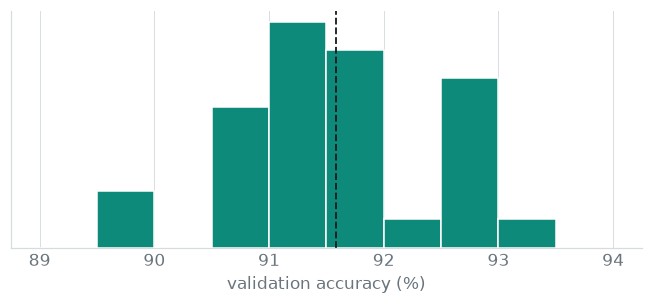

mean 91.6%   standard deviation 0.89   range 89.7% to 93.2%   spread 3.4 points


In [3]:
a = np.array([run(s) for s in range(30)])
plt.figure(figsize=(7.4, 2.8)); plt.hist(a, bins=np.arange(np.floor(a.min()), np.ceil(a.max()) + 0.5, 0.5), color=style.TEAL, edgecolor="white")
plt.axvline(a.mean(), color=style.INK, ls="--", lw=1.2); plt.xlabel("validation accuracy (%)"); plt.yticks([]); plt.show()
print(f"mean {a.mean():.1f}%   standard deviation {a.std(ddof=1):.2f}   range {a.min():.1f}% to {a.max():.1f}%   spread {a.max() - a.min():.1f} points")

Same code, same data, same hyperparameters. Only the random seed differs, and it moves the result by
several points.

## A comparison that can go either way

Now compare two configurations: a hidden width of 64 against 72. First with one run each, repeated many
times to see how often the single-run comparison picks each side. Then with the means.

In [4]:
b = np.array([run(100 + s, hidden=72) for s in range(30)])
wins = np.mean(b > a); print(f"the wider network wins {wins:.0%} of single-run comparisons and loses or ties {1 - wins:.0%}")
diff = b.mean() - a.mean(); se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
print(f"difference of means {diff:+.2f} points, standard error {se:.2f}, so {abs(diff) / se:.1f} standard errors from zero")

the wider network wins 83% of single-run comparisons and loses or ties 17%
difference of means +0.69 points, standard error 0.22, so 3.1 standard errors from zero


The standard error of a mean is the standard deviation of the runs divided by the square root of how
many there were. A difference is worth believing when it is several standard errors from zero.

## How many seeds are enough?

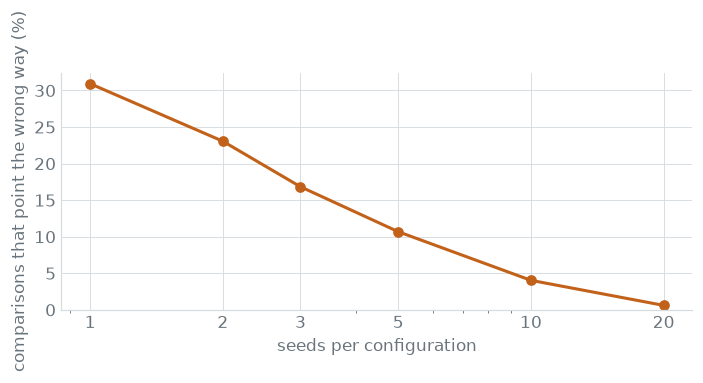

In [5]:
rng = np.random.default_rng(0); ns = [1, 2, 3, 5, 10, 20]
flip = [np.mean([(rng.choice(b, n).mean() > rng.choice(a, n).mean()) != (diff > 0) for _ in range(4000)]) * 100 for n in ns]
plt.figure(figsize=(7.4, 2.8)); plt.plot(ns, flip, marker="o", color=style.ORANGE); plt.xscale("log"); plt.xticks(ns, ns)
plt.xlabel("seeds per configuration"); plt.ylabel("comparisons that point the wrong way (%)"); plt.ylim(0, None); plt.show()

## Things to try

- Fix the weight initialisation and vary only the data order, or the reverse. Which contributes more?
- Train for longer. Does the spread across seeds shrink?
- Repeat with a much smaller training set. What happens to the spread?